
# Experiment Analysis: 15 Computers, 5 Printers

This notebook reads the metric tables directly from [`RESULTS.md`](RESULTS.md), displays them as data tables, and plots the mean and standard deviation across seeds for normal operation, 20% message loss, and full partition.

The plots are exported as PNG files in `figures/` and displayed inline. The notebook creates `figures/` if it does not exist and uses ImageMagick (`magick` or `convert`) to rasterize the charts. Run the notebook from the repository root (or a subdirectory beneath it). The values are the rounded values in `RESULTS.md`; use the experiment CSVs when you need full precision.


In [1]:

from pathlib import Path
import html
import math
import re
import shutil
import subprocess

from IPython.display import Image, Markdown, display

# Find the repository root from the current notebook working directory.
ROOT = Path.cwd().resolve()
while not (ROOT / "RESULTS.md").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "RESULTS.md").is_file():
    raise FileNotFoundError("Could not find RESULTS.md above the notebook directory")

FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = ROOT / "RESULTS.md"
text = RESULTS_PATH.read_text(encoding="utf-8")
print(f"Reading tables from {RESULTS_PATH}")


Reading tables from /home/rafomiya/Desktop/unicamp/8s/distribuidos/distributed-algorithms/RESULTS.md



## Read the report tables

The parser takes the rows under each report heading and converts every `mean ± standard deviation` cell into numeric values. This keeps the notebook aligned with the report while making the data available for charting.


In [2]:

def markdown_table(section_title):
    """Return the header and data rows from a Markdown section table."""
    lines = text.splitlines()
    heading = f"## {section_title}"
    try:
        start = next(i for i, line in enumerate(lines) if line.strip() == heading) + 1
    except StopIteration as exc:
        raise ValueError(f"Missing section: {section_title}") from exc

    table_lines = []
    for line in lines[start:]:
        if line.startswith("## "):
            break
        if line.strip().startswith("|"):
            table_lines.append(line.strip())

    rows = []
    for line in table_lines:
        row = [cell.strip() for cell in line.strip("|").split("|")]
        if row and set(row[0]) != {"-"}:
            rows.append(row)
    if len(rows) < 2:
        raise ValueError(f"No data table found in section: {section_title}")
    return rows[0], rows[1:]


def parse_mean_sd(value):
    mean_text, sd_text = value.split("±", maxsplit=1)
    return float(mean_text.replace(",", "").strip()), float(sd_text.replace(",", "").strip())


def parse_metric_section(section_title):
    headers, rows = markdown_table(section_title)
    output = []
    for row in rows:
        item = {"scenario": row[0]}
        for header, value in zip(headers[1:], row[1:]):
            item[header] = parse_mean_sd(value)
        output.append(item)
    return output


ra_rows = parse_metric_section("Ricart–Agrawala")
gossip_rows = parse_metric_section("Gossip")
throughput_headers, throughput_raw = markdown_table("System throughput")
throughput_rows = [
    {"scenario": row[0], "Throughput (jobs/s)": parse_mean_sd(row[1])}
    for row in throughput_raw
]

scenario_order = ["Normal", "20% loss", "Full partition"]
plot_scenario_labels = ["Normal", "20% de perda", "Full partition"]
for label, rows in (("Ricart–Agrawala", ra_rows), ("Gossip", gossip_rows), ("System throughput", throughput_rows)):
    found = [row["scenario"] for row in rows]
    if found != scenario_order:
        raise ValueError(f"Unexpected scenario order in {label}: {found}")

print(f"Loaded {len(ra_rows)} RA rows, {len(gossip_rows)} Gossip rows, and {len(throughput_rows)} throughput rows.")


Loaded 3 RA rows, 3 Gossip rows, and 3 throughput rows.


In [3]:

def show_table(title, rows):
    headers = list(rows[0])
    lines = [f"### {title}", "", "| " + " | ".join(headers) + " |",
             "|" + "|".join(["---"] * len(headers)) + "|"]
    for row in rows:
        values = []
        for header in headers:
            value = row[header]
            values.append(f"{value[0]:,.2f} ± {value[1]:,.2f}" if isinstance(value, tuple) else str(value))
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

show_table("Ricart–Agrawala", ra_rows)
show_table("Gossip", gossip_rows)
show_table("System throughput", throughput_rows)


### Ricart–Agrawala

| scenario | Mean acquisition (ms) | p50 (ms) | p95 (ms) | p99 (ms) | REQUEST/REPLY attempts | Application bytes |
|---|---|---|---|---|---|---|
| Normal | 978.48 ± 5.31 | 988.84 ± 13.40 | 1,663.72 ± 20.62 | 1,722.64 ± 14.95 | 5,782.00 ± 105.00 | 1,014,232.00 ± 19,598.00 |
| 20% loss | 1,148.39 ± 33.25 | 1,145.91 ± 31.49 | 1,915.62 ± 89.14 | 1,992.43 ± 87.19 | 6,731.00 ± 329.00 | 1,160,815.00 ± 57,076.00 |
| Full partition | 1,418.27 ± 60.66 | 1,454.21 ± 81.54 | 2,070.27 ± 66.24 | 2,155.28 ± 54.32 | 11,286.00 ± 650.00 | 1,948,722.00 ± 113,334.00 |

### Gossip

| scenario | Mean convergence (ms) | p50 (ms) | p95 (ms) | p99 (ms) | Push-pull attempts | Application bytes |
|---|---|---|---|---|---|---|
| Normal | 258.31 ± 9.86 | 255.65 ± 22.97 | 346.67 ± 5.33 | 369.41 ± 15.86 | 326.00 ± 4.00 | 2,562,018.00 ± 68,667.00 |
| 20% loss | 374.83 ± 16.93 | 367.32 ± 21.90 | 498.06 ± 2.87 | 543.76 ± 33.11 | 390.00 ± 3.00 | 2,996,280.00 ± 74,406.00 |
| Full partition | 258.08 ± 10.78 | 257.91 ± 8.90 | 345.38 ± 34.02 | 371.91 ± 37.46 | 413.00 ± 9.00 | 2,731,481.00 ± 51,044.00 |

### System throughput

| scenario | Throughput (jobs/s) |
|---|---|
| Normal | 20.79 ± 0.44 |
| 20% loss | 17.13 ± 0.05 |
| Full partition | 17.22 ± 0.42 |


## Export the tables as LaTeX

Run a cell below to print a copyable LaTeX `table` environment. The generated tables include the mean and sample standard deviation across seeds.


In [4]:
def latex_escape(value):
    bs = chr(92)
    replacements = {
        bs: bs + "textbackslash{}", "&": bs + "&", "%": bs + "%",
        "$": bs + "$", "#": bs + "#", "_": bs + "_", "{": bs + "{",
        "}": bs + "}", "~": bs + "textasciitilde{}", "^": bs + "textasciicircum{}",
    }
    return "".join(replacements.get(char, char) for char in str(value))


def latex_table(caption, label, rows, precisions):
    """Build a LaTeX table with scenarios as rows and metrics as columns."""
    bs = chr(92)
    row_end = " " + bs * 2
    metric_headers = list(rows[0])[1:]
    columns = "l" + "r" * len(metric_headers)
    lines = [
        bs + "begin{table}[t]",
        bs + "centering",
        bs + "caption{" + latex_escape(caption) + "}",
        bs + "label{" + label + "}",
        bs + "begingroup",
        bs + "tiny",
        bs + "setlength{" + bs + "tabcolsep}{1.5pt}",
        bs + "begin{tabular}{" + columns + "}",
        bs + "hline",
        "Scenario & " + " & ".join(latex_escape(metric) for metric in metric_headers) + row_end,
        bs + "hline",
    ]
    for row in rows:
        cells = [latex_escape(row["scenario"])]
        for metric, precision in zip(metric_headers, precisions):
            mean, sd = row[metric]
            number = f"{mean:,.{precision}f} {bs}pm {sd:,.{precision}f}"
            cells.append("$" + number + "$")
        lines.append(" & ".join(cells) + row_end)
    lines.extend([
        bs + "hline",
        bs + "end{tabular}",
        bs + "endgroup",
        bs + "end{table}",
    ])
    return chr(10).join(lines)


In [5]:

print(latex_table(
    "Ricart--Agrawala metrics (mean and sample standard deviation across seeds)",
    "tab:ricart-agrawala",
    ra_rows,
    [2, 2, 2, 2, 0, 0],
))


\begin{table}[t]
\centering
\caption{Ricart--Agrawala metrics (mean and sample standard deviation across seeds)}
\label{tab:ricart-agrawala}
\begingroup
\tiny
\setlength{\tabcolsep}{1.5pt}
\begin{tabular}{lrrrrrr}
\hline
Scenario & Mean acquisition (ms) & p50 (ms) & p95 (ms) & p99 (ms) & REQUEST/REPLY attempts & Application bytes \\
\hline
Normal & $978.48 \pm 5.31$ & $988.84 \pm 13.40$ & $1,663.72 \pm 20.62$ & $1,722.64 \pm 14.95$ & $5,782 \pm 105$ & $1,014,232 \pm 19,598$ \\
20\% loss & $1,148.39 \pm 33.25$ & $1,145.91 \pm 31.49$ & $1,915.62 \pm 89.14$ & $1,992.43 \pm 87.19$ & $6,731 \pm 329$ & $1,160,815 \pm 57,076$ \\
Full partition & $1,418.27 \pm 60.66$ & $1,454.21 \pm 81.54$ & $2,070.27 \pm 66.24$ & $2,155.28 \pm 54.32$ & $11,286 \pm 650$ & $1,948,722 \pm 113,334$ \\
\hline
\end{tabular}
\endgroup
\end{table}


In [6]:

print(latex_table(
    "Gossip metrics (mean and sample standard deviation across seeds)",
    "tab:gossip",
    gossip_rows,
    [2, 2, 2, 2, 0, 0],
))


\begin{table}[t]
\centering
\caption{Gossip metrics (mean and sample standard deviation across seeds)}
\label{tab:gossip}
\begingroup
\tiny
\setlength{\tabcolsep}{1.5pt}
\begin{tabular}{lrrrrrr}
\hline
Scenario & Mean convergence (ms) & p50 (ms) & p95 (ms) & p99 (ms) & Push-pull attempts & Application bytes \\
\hline
Normal & $258.31 \pm 9.86$ & $255.65 \pm 22.97$ & $346.67 \pm 5.33$ & $369.41 \pm 15.86$ & $326 \pm 4$ & $2,562,018 \pm 68,667$ \\
20\% loss & $374.83 \pm 16.93$ & $367.32 \pm 21.90$ & $498.06 \pm 2.87$ & $543.76 \pm 33.11$ & $390 \pm 3$ & $2,996,280 \pm 74,406$ \\
Full partition & $258.08 \pm 10.78$ & $257.91 \pm 8.90$ & $345.38 \pm 34.02$ & $371.91 \pm 37.46$ & $413 \pm 9$ & $2,731,481 \pm 51,044$ \\
\hline
\end{tabular}
\endgroup
\end{table}


In [7]:

print(latex_table(
    "System throughput (mean and sample standard deviation across seeds)",
    "tab:throughput",
    throughput_rows,
    [2],
))


\begin{table}[t]
\centering
\caption{System throughput (mean and sample standard deviation across seeds)}
\label{tab:throughput}
\begingroup
\tiny
\setlength{\tabcolsep}{1.5pt}
\begin{tabular}{lr}
\hline
Scenario & Throughput (jobs/s) \\
\hline
Normal & $20.79 \pm 0.44$ \\
20\% loss & $17.13 \pm 0.05$ \\
Full partition & $17.22 \pm 0.42$ \\
\hline
\end{tabular}
\endgroup
\end{table}



## Como interpretar os gráficos

- A altura das barras mostra a média das três seeds; as barras de erro indicam ±1 desvio padrão amostral.
- As barras de latência comparam média, p50, p95 e p99 em cada cenário; p95 e p99 destacam a cauda da distribuição.
- As tentativas e os bytes são totais por ensaio medido (45 trabalhos), não por trabalho. As tentativas dos dois algoritmos aparecem em gráficos separados porque suas escalas são muito diferentes.
- A vazão é medida no intervalo do ensaio após o aquecimento. O ensaio de partição inclui 0,4 s de bloqueio e a recuperação.
- Como há apenas três seeds, os desvios padrão descrevem este conjunto de execuções e não são estimativas precisas da variabilidade de toda a população.


In [8]:

COLORS = ["#2563eb", "#0f766e", "#d97706", "#9333ea", "#dc2626"]


def svg_grouped_bar_chart(title, y_label, series, filename, value_format="number"):
    """Draw grouped mean bars with ±1 SD error bars as a self-contained SVG."""
    width, height = 980, 520
    left, right, top, bottom = 90, 40, 92, 94
    plot_w, plot_h = width - left - right, height - top - bottom
    group_w = plot_w / len(scenario_order)

    scaled = [value + error for item in series
              for value, error in zip(item["values"], item["errors"])]
    max_value = max(scaled) if scaled else 1
    y_max = max(1.0, max_value * 1.12)
    tick_count = 5
    plot_bottom = top + plot_h

    def y(value):
        return top + plot_h * (1 - value / y_max)

    def tick_label(value):
        if value_format == "ms":
            return f"{value:,.0f}"
        if value_format == "mib":
            return f"{value:,.1f}"
        return f"{value:,.0f}"

    pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">']
    pieces.append('<rect width="100%" height="100%" fill="white"/>')
    pieces.append(f'<text x="{width/2}" y="30" text-anchor="middle" font-family="sans-serif" font-size="20" font-weight="bold">{html.escape(title)}</text>')

    for i in range(tick_count + 1):
        value = y_max * i / tick_count
        yy = y(value)
        pieces.append(f'<line x1="{left}" y1="{yy:.1f}" x2="{left+plot_w}" y2="{yy:.1f}" stroke="#d1d5db" stroke-width="1"/>')
        pieces.append(f'<text x="{left-12}" y="{yy+4:.1f}" text-anchor="end" font-family="sans-serif" font-size="12" fill="#374151">{tick_label(value)}</text>')

    pieces.append(f'<line x1="{left}" y1="{top}" x2="{left}" y2="{plot_bottom}" stroke="#111827"/>')
    pieces.append(f'<line x1="{left}" y1="{plot_bottom}" x2="{left+plot_w}" y2="{plot_bottom}" stroke="#111827"/>')
    pieces.append(f'<text x="22" y="{top+plot_h/2}" transform="rotate(-90 22 {top+plot_h/2})" text-anchor="middle" font-family="sans-serif" font-size="14">{html.escape(y_label)}</text>')

    # Compact one-row legend above the plotting area.
    legend_step = plot_w / max(1, len(series))
    for index, item in enumerate(series):
        color = COLORS[index % len(COLORS)]
        legend_x = left + index * legend_step
        pieces.append(f'<rect x="{legend_x:.1f}" y="57" width="13" height="13" fill="{color}" rx="2"/>')
        pieces.append(f'<text x="{legend_x+19:.1f}" y="68" font-family="sans-serif" font-size="12" fill="#111827">{html.escape(item["label"])}</text>')

    n_series = max(1, len(series))
    bar_w = min(44.0, group_w / (n_series * 1.35))
    gap = min(9.0, bar_w * 0.22)
    total_w = n_series * bar_w + (n_series - 1) * gap
    for group_index, scenario in enumerate(plot_scenario_labels):
        center = left + group_w * (group_index + 0.5)
        pieces.append(f'<text x="{center:.1f}" y="{plot_bottom+27}" text-anchor="middle" font-family="sans-serif" font-size="13" fill="#111827">{html.escape(scenario)}</text>')
        start_x = center - total_w / 2
        for series_index, item in enumerate(series):
            value = item["values"][group_index]
            error = item["errors"][group_index]
            x = start_x + series_index * (bar_w + gap)
            bar_top = y(value)
            bar_height = plot_bottom - bar_top
            color = COLORS[series_index % len(COLORS)]
            pieces.append(f'<rect x="{x:.1f}" y="{bar_top:.1f}" width="{bar_w:.1f}" height="{bar_height:.1f}" fill="{color}" rx="2"/>')
            err_top = y(min(y_max, value + error))
            err_bottom = y(max(0, value - error))
            mid = x + bar_w / 2
            pieces.append(f'<line x1="{mid:.1f}" y1="{err_top:.1f}" x2="{mid:.1f}" y2="{err_bottom:.1f}" stroke="#111827" stroke-width="1.5"/>')
            pieces.append(f'<line x1="{mid-5:.1f}" y1="{err_top:.1f}" x2="{mid+5:.1f}" y2="{err_top:.1f}" stroke="#111827" stroke-width="1.5"/>')
            pieces.append(f'<line x1="{mid-5:.1f}" y1="{err_bottom:.1f}" x2="{mid+5:.1f}" y2="{err_bottom:.1f}" stroke="#111827" stroke-width="1.5"/>')

    pieces.append(f'<text x="{width/2}" y="{height-18}" text-anchor="middle" font-family="sans-serif" font-size="13" fill="#374151">Cenário</text>')
    pieces.append('</svg>')
    svg = "\n".join(pieces)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    output_path = FIGURES_DIR / filename
    converter = shutil.which("magick") or shutil.which("convert")
    if converter is None:
        raise RuntimeError("ImageMagick is required: install `magick` or `convert` to export PNG charts")
    command = [converter]
    if Path(converter).name == "magick":
        command.append("convert")
    command.extend(["svg:-", str(output_path)])
    subprocess.run(command, input=(svg + "\n").encode("utf-8"), check=True)
    display(Image(filename=str(output_path)))
    print(f"Salvo: {output_path.relative_to(ROOT)}")


def series_from(rows, column, label=None, scale=1.0):
    pairs = [row[column] for row in rows]
    return {
        "label": label or column,
        "values": [pair[0] * scale for pair in pairs],
        "errors": [pair[1] * scale for pair in pairs],
    }


Salvo: figures/ra_latency.png


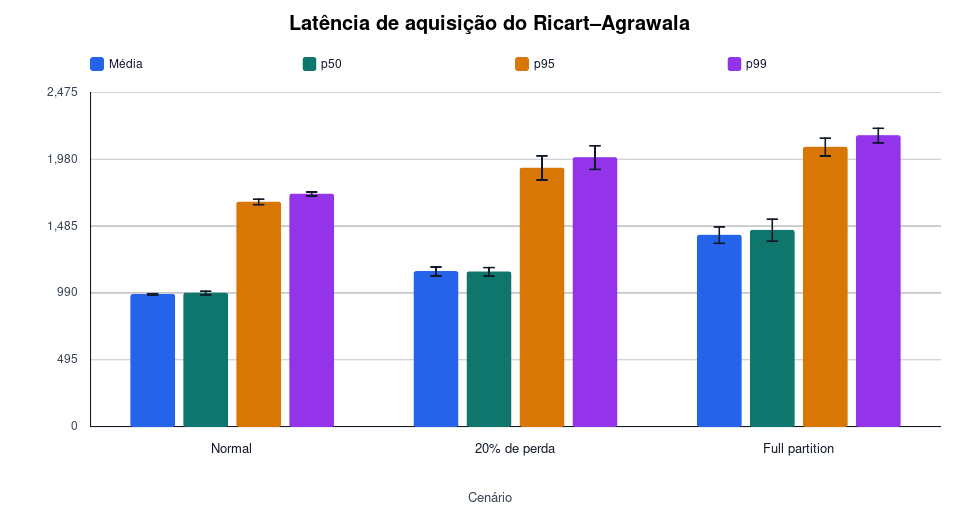

In [9]:

ra_latency_series = [
    series_from(ra_rows, "Mean acquisition (ms)", "Média"),
    series_from(ra_rows, "p50 (ms)", "p50"),
    series_from(ra_rows, "p95 (ms)", "p95"),
    series_from(ra_rows, "p99 (ms)", "p99"),
]
svg_grouped_bar_chart("Latência de aquisição do Ricart–Agrawala", "Latência (ms)", ra_latency_series, "ra_latency.png", value_format="ms")


Salvo: figures/gossip_convergence.png


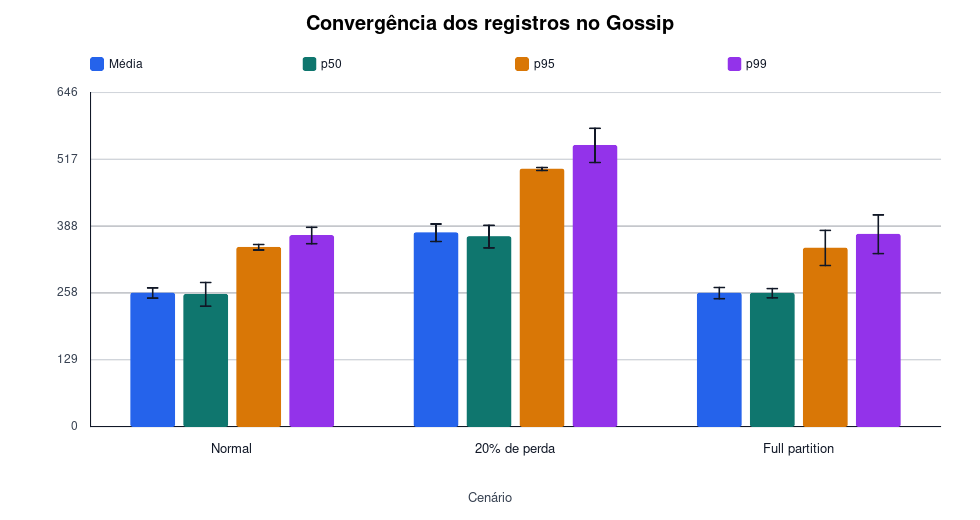

In [10]:

gossip_latency_series = [
    series_from(gossip_rows, "Mean convergence (ms)", "Média"),
    series_from(gossip_rows, "p50 (ms)", "p50"),
    series_from(gossip_rows, "p95 (ms)", "p95"),
    series_from(gossip_rows, "p99 (ms)", "p99"),
]
svg_grouped_bar_chart("Convergência dos registros no Gossip", "Latência de convergência (ms)", gossip_latency_series, "gossip_convergence.png", value_format="ms")


Salvo: figures/ra_attempts.png
Salvo: figures/gossip_attempts.png


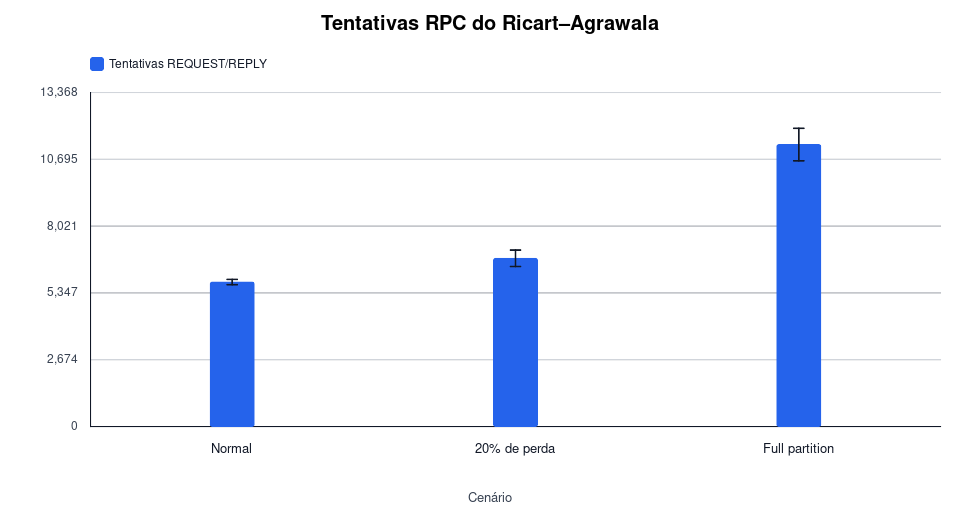

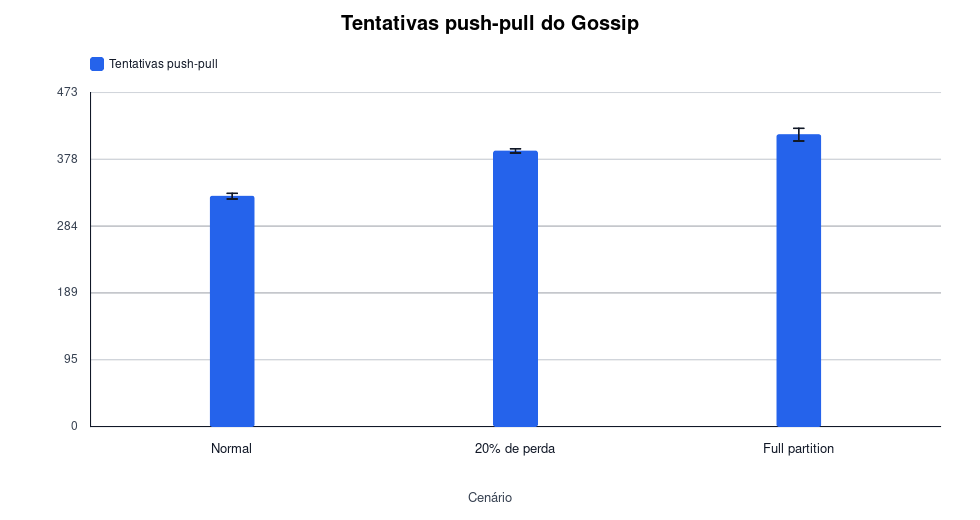

In [11]:

ra_traffic = [series_from(ra_rows, "REQUEST/REPLY attempts", "Tentativas REQUEST/REPLY")]
svg_grouped_bar_chart("Tentativas RPC do Ricart–Agrawala", "Tentativas por ensaio", ra_traffic, "ra_attempts.png")

gossip_traffic = [series_from(gossip_rows, "Push-pull attempts", "Tentativas push-pull")]
svg_grouped_bar_chart("Tentativas push-pull do Gossip", "Tentativas por ensaio", gossip_traffic, "gossip_attempts.png")


Salvo: figures/rpc_volume.png


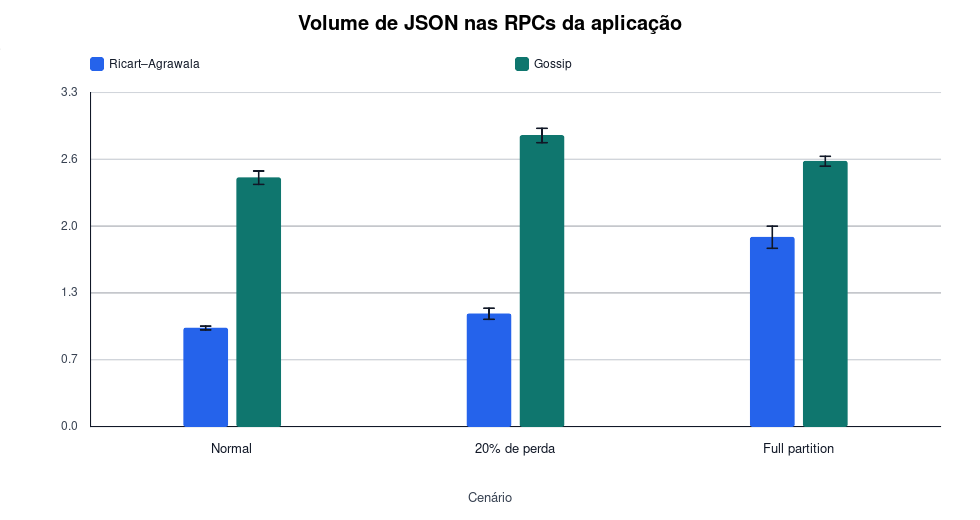

In [12]:

byte_series = [
    series_from(ra_rows, "Application bytes", "Ricart–Agrawala", scale=1 / (1024**2)),
    series_from(gossip_rows, "Application bytes", "Gossip", scale=1 / (1024**2)),
]
svg_grouped_bar_chart("Volume de JSON nas RPCs da aplicação", "Volume de JSON (MiB)", byte_series, "rpc_volume.png", value_format="mib")


Salvo: figures/throughput.png


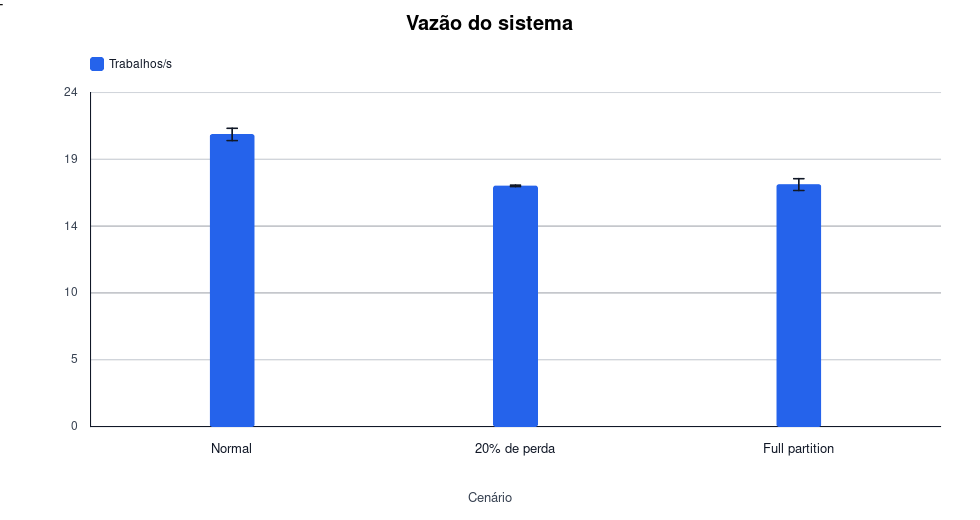

In [13]:

throughput_series = [series_from(throughput_rows, "Throughput (jobs/s)", "Trabalhos/s")]
svg_grouped_bar_chart("Vazão do sistema", "Trabalhos por segundo", throughput_series, "throughput.png", value_format="number")



## Reading the plots

- Latency points and error bars summarize the three seeds; p95 and p99 show tail behavior.
- Attempt and byte plots are totals per measured trial (45 jobs), not per job.
- Throughput is measured over the trial interval after warmup. The partition trial includes its 0.4-second blocked interval and recovery.
- With only three seeds, the standard deviations describe this run set and should not be treated as precise estimates of population variability.
